<a href="https://colab.research.google.com/github/profecarlosrico/NovaRetail/blob/main/S8_Student_Version_Project_NovaRetail_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ¡Hola Carlos!

Mi nombre es Israel, estaré ayudándote a revisar este proyecto para que quede en su mejor versión.

Para simular la dinámica de un ambiente de trabajo, si veo algún error, en primer instancia solo los señalaré, dándote la oportunidad de encontrarlos y corregirlos por tu cuenta. Esto es útil para que te acostumbres a un escenario laboral. En caso de que no puedas resolver la tarea, te daré una información más precisa en la próxima revisión.

Encontrarás mis comentarios más abajo - **por favor, no los muevas, no los modifiques ni los borres**.

¿Cómo funciona esta revisión? Leeré atentamente tu código y te señalaré tus fortalezas y aquellas cosas que podemos mejorar. Los comentarios aparecerán de esta forma:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si todo está perfecto y no se requieren cambios en el código.
</div>


<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta. Se aceptan uno o dos comentarios de este tipo en el borrador, pero si hay más, deberás hacer las correcciones.
</div>

<div class="alert alert-block alert-danger">

<b>Comentario del revisor</b> <a class="tocSkip"></a>

Si definitivamente hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma si algo no queda claro (copia este código en una celda markdown):

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class="tocSkip"></a>

Hola, muchas gracias por tus comentarios y la revisión.        
</div>

**Es un gusto acompañarte en este proceso, ¡empecemos!**

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [7]:
# Importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt




### Cargar Dataset

In [8]:
# Cargar el dataset y explorar datos
df = pd.read_csv("/content/drive/MyDrive/Bootcamp DA/Sprint 8/Proyecto/novaretail_comportamiento_clientes_2024.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [9]:
# mostrar las primeras 5 filas
display(df.head())

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Excelente trabajo, la carga, revisión de tipos y vista inicial del dataset son correctas.
</div>

## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`

- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`


La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad`, podría ser int64, pues no se requiere valores decimales.

**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [10]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [11]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [12]:
# Estadísticas descriptivas de variables numéricas
df.describe()


,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,0.139267,0.150733,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,0.346236,0.357801,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000,0.000000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,0.000000,0.000000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,0.000000,0.000000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,1.000000,1.000000,244.690000


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables numéricas

- `edad` — oscila entre 18 y 75 años, con una media en 38 años.
- `nivel_ingreso`- presenta un promedio de 30019.7, desde un mínimo de 8000 a un máximo de 74000
- `visitas_mes` - tienen una media y una mediana muy similares, cerca de 10 y un máximo de 25 visitas al mes.
- `compras_mes` - se distingue un máximo de 8 compras al mes, frente a un promedio de 1.2.
- `gasto_publicidad_dirigida` - va desde 0 hasta 75 con un promedio 20.14 y una mediana 19.73
- `satisfaccion`- presenta una media y una mediana de 3.6
- `ingreso_anual`- Ingreso anual generado por el cliente para la empresa, presenta una diferencia entre el promedio (36.59) y la media (30.7) con un máximo de 244.69


#### Explorar variables binarias

In [13]:
# Verificar que cada columna tenga únicamente dos valores posibles
print('Columna miembro_premium: ', df['miembro_premium'].unique())
print('Cantidad de miembro_premium: ', df['miembro_premium'].sum())
print('Columna abandono ', df['abandono'].unique())
print('Cantidad de abandono ', df['abandono'].sum())

Columna miembro_premium:  [0 1]
Cantidad de miembro_premium:  2089
Columna abandono  [0 1]
Cantidad de abandono  2261


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables binarias

- `miembro_premium` — tiene los dos valores esperados de 0 (falso) y 1 (verdadero, es miembro premium), para un total de 2089 de 15000 miembros registrados
- `abandono` — tiene los dos valores esperados de 0 (falso) y 1 (verdadero, abandono), para un total de 2261 de 15000 miembros registrados

#### Explorar variables categóricas

In [14]:
# Verificar el número de valores únicos por variable categórica
print('Clientes ', df["id_cliente"].describe())
#reportar proporciones por dispositivo y región.
print('Tipos de dispositivos', df["tipo_dispositivo"].unique())
print('Regiones ', df["region"].unique())

Clientes  count         15000
unique        15000
top       CL-100000
freq              1
Name: id_cliente, dtype: object
Tipos de dispositivos ['móvil' 'tablet' 'escritorio']
Regiones  ['norte' 'sur' 'este' 'oeste']


In [15]:
# Explorar variables categóricas y cómo se distribuyen
valor_tipo_dispositivo = df["tipo_dispositivo"].value_counts()
print('Cantidad por tipo de dispositivo: \n', valor_tipo_dispositivo)
valor_region=df["region"].value_counts()
print('Cantidad por región: \n', valor_region)

#tipos_disp x cliente
conteo = df["tipo_dispositivo"].value_counts()
proporcion = df["tipo_dispositivo"].value_counts(normalize=True)
tabla = pd.DataFrame({'conteo': conteo, 'proporcion': proporcion})
print(tabla)
#clientes x region
conteo = df["region"].value_counts()
proporcion = df["region"].value_counts(normalize=True)
tabla = pd.DataFrame({'conteo': conteo, 'proporcion': proporcion})
print(tabla)

Cantidad por tipo de dispositivo: 
 tipo_dispositivo
móvil         9818
escritorio    3720
tablet        1462
Name: count, dtype: int64
Cantidad por región: 
 region
norte    4395
oeste    3810
sur      3726
este     3069
Name: count, dtype: int64
                  conteo  proporcion
tipo_dispositivo                    
móvil               9818    0.654533
escritorio          3720    0.248000
tablet              1462    0.097467
        conteo  proporcion
region                    
norte     4395      0.2930
oeste     3810      0.2540
sur       3726      0.2484
este      3069      0.2046


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves (resalta un detalle relevante por columna)

Diagnóstico inicial de variables categóricas
- `Id_cliente`- Hay 15000 registros de valores únicos, lo que indica que no hay duplicados, nulos ni faltantes.
- `tipo_dispositivo` — hay tres tipos identificados: móvil, tablet y escritorio. Con un predominio del móvil con 9818 apariciones.
- `region` - presenta 4 regiones: norte, sur, este y oeste con mayor presencia del norte con 4395 apariciones.


### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Buen trabajo, identificas categorías y frecuencias pero falta comprobar `id_cliente` y reportar proporciones por dispositivo y región.
</div>

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

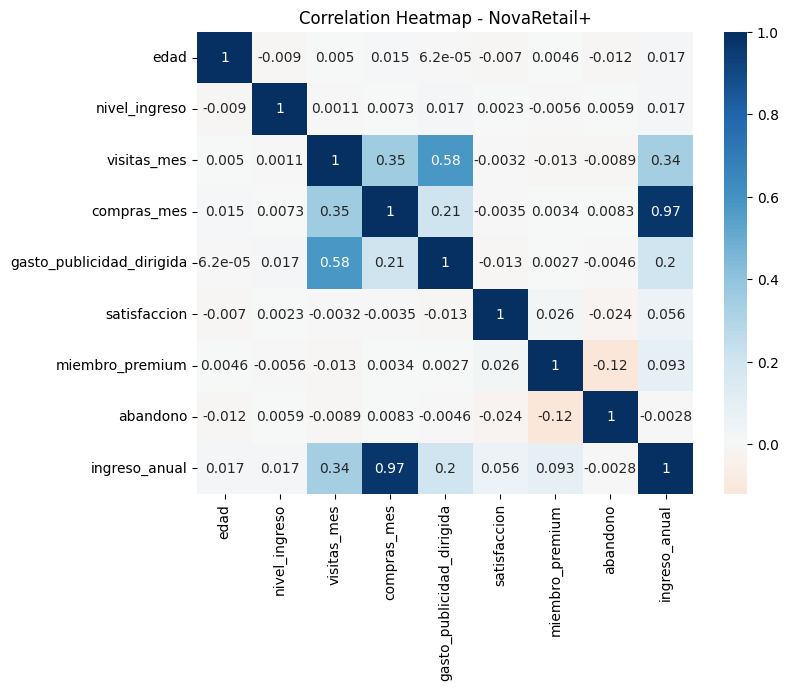

In [23]:
# Visualizar la matriz de correlación para identificar relaciones
# matriz de correlación (especificando únicamente columnas numéricas)
corr = df.corr(numeric_only=True)
# Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="RdBu", center=0)
plt.title("Correlation Heatmap - NovaRetail+")
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves


Observaciones generales (Heatmap)  
- Se observan correlaciones que merecen ser analizadas: ingreso_anual x compras_mes y gasto_publicidad_dirigida x visitas_mes


Observaciones respecto a `ingreso_anual`  
- Presenta una correlación de 0.97 con compras_mes, siendo la más alta.


### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - En el Scatterplot o gráfico de dispersión permite ver la relación entre las columnas numéricas resaltando ingreso_anual en relación con las demás variables numéricas (edad, nivel_ingreso, visitas_mes, compras_mes, gasto_publicidad_dirigida,	satisfaccion) que muestra un movimiento conjunto positivo, no una causalidad.


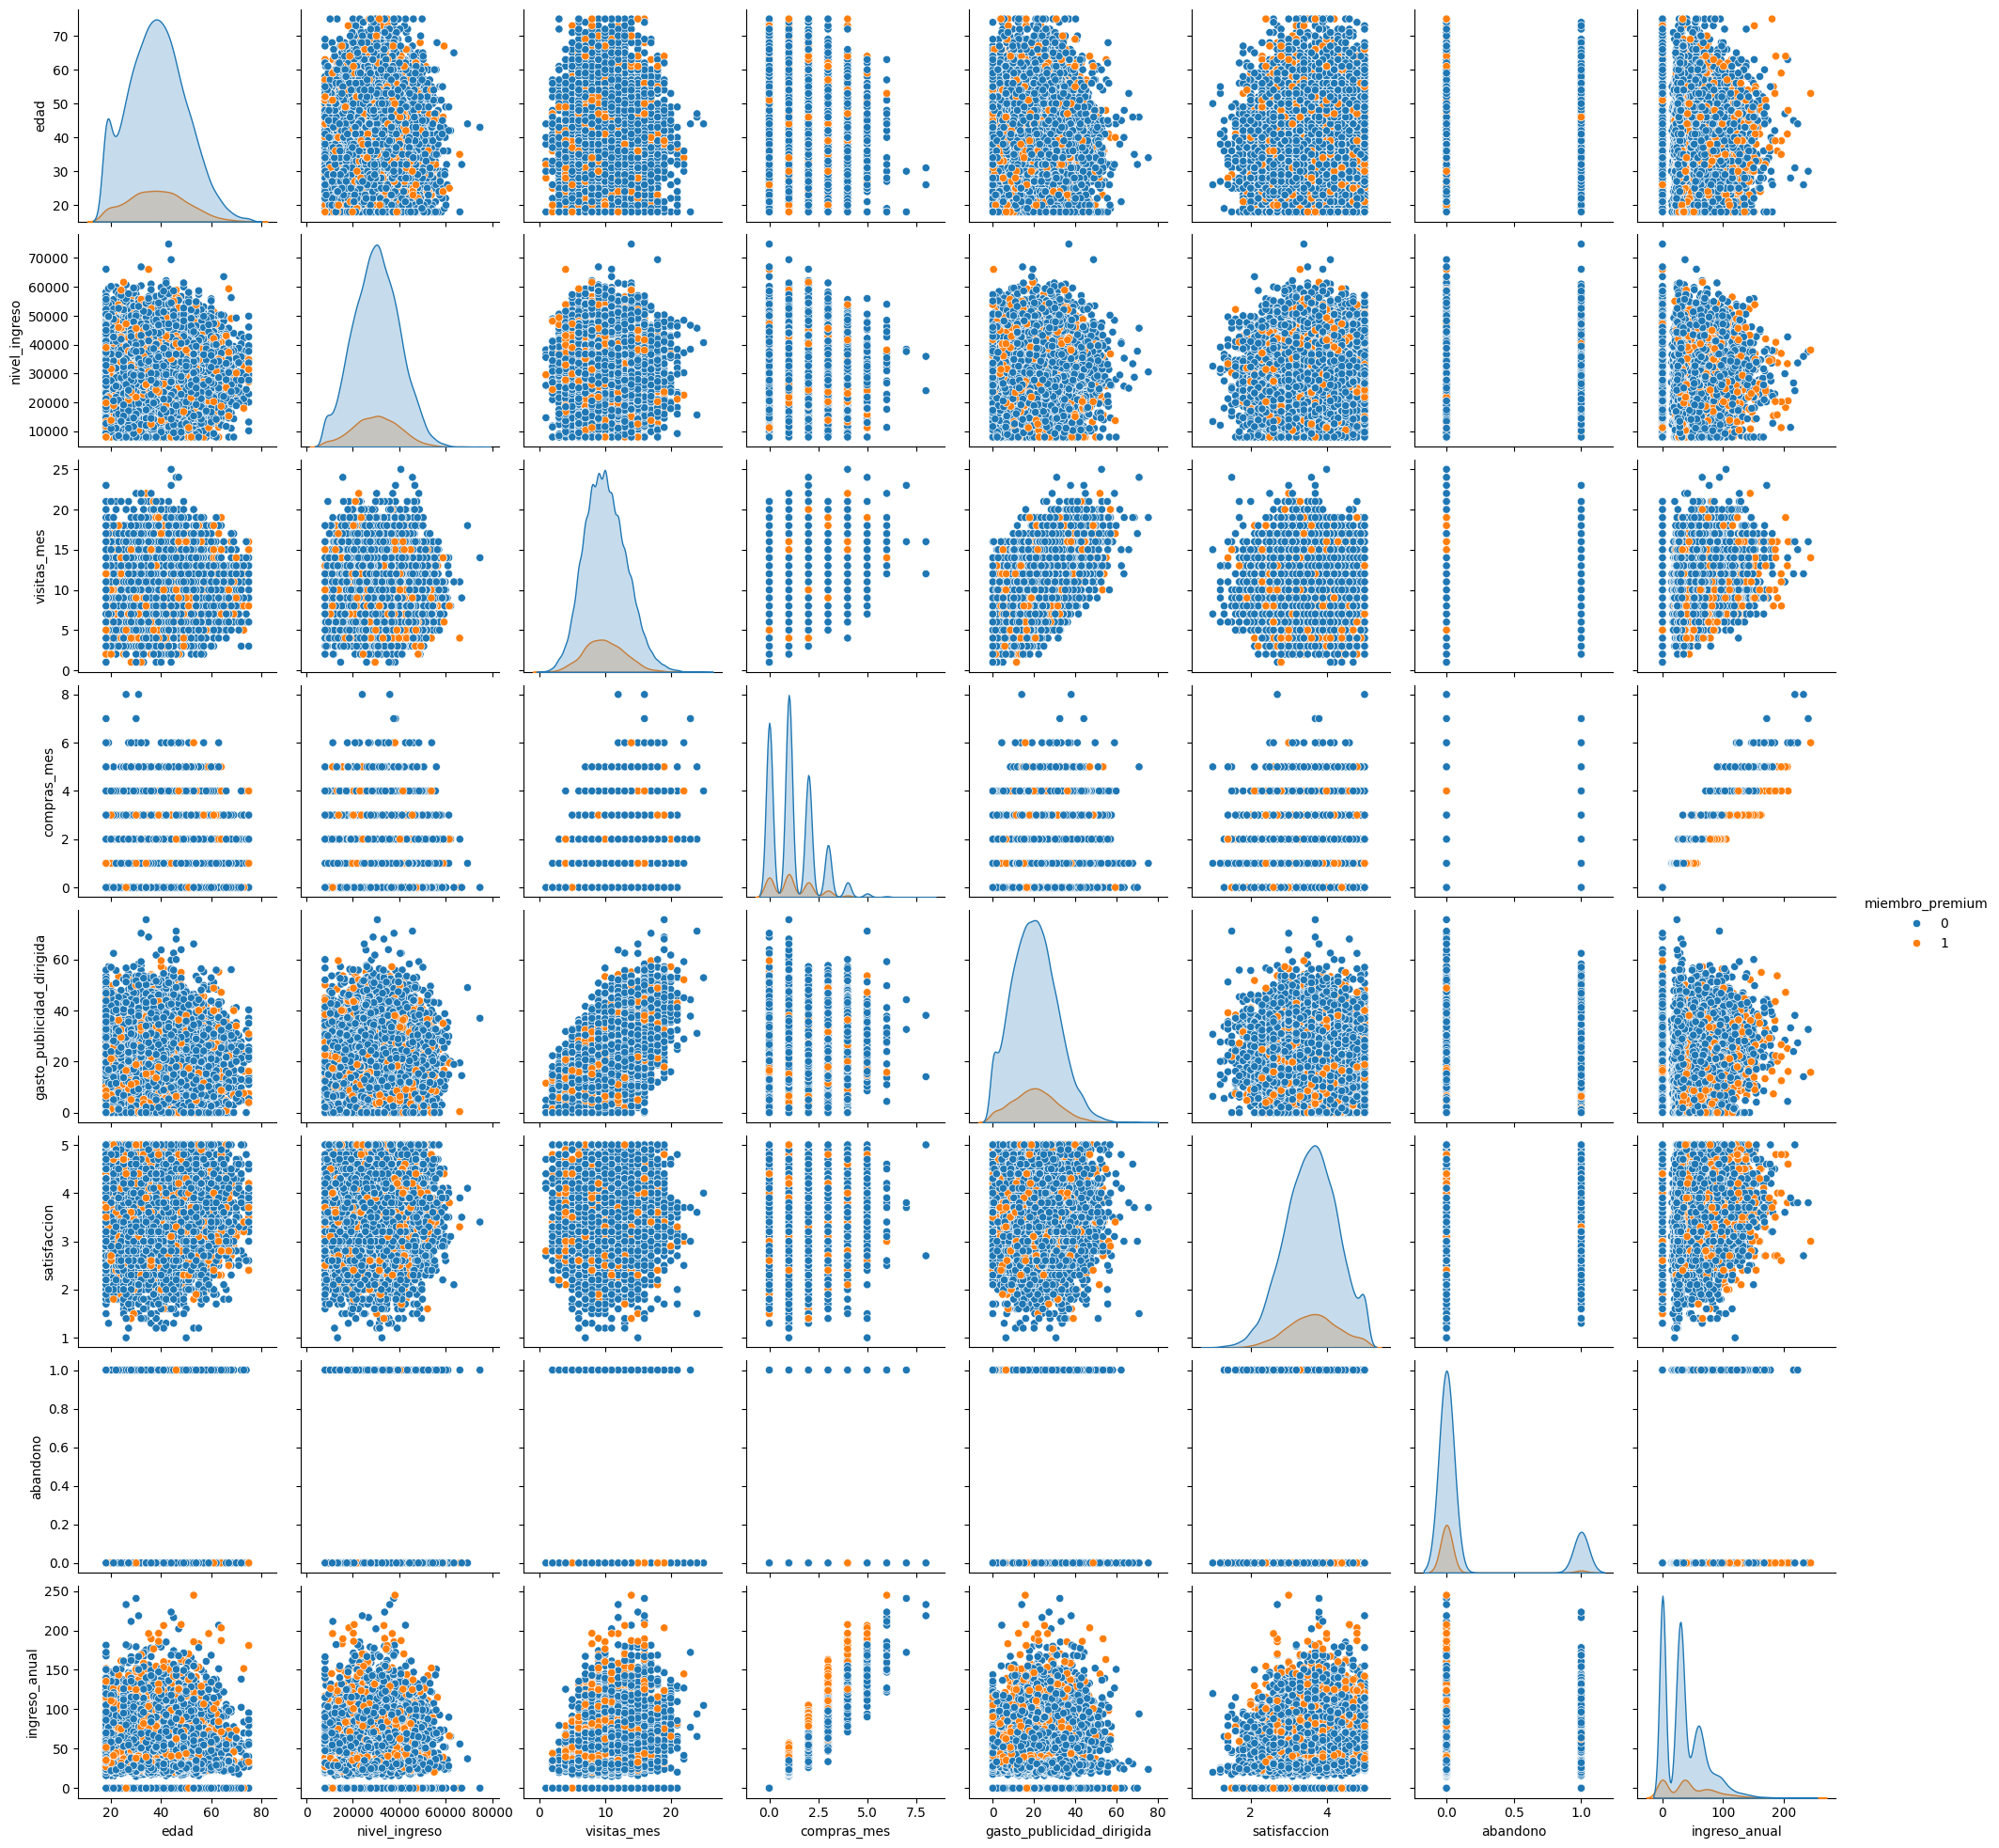

In [18]:
sns.pairplot(df, hue="miembro_premium")
plt.show()

### Scatterplot para pares clave

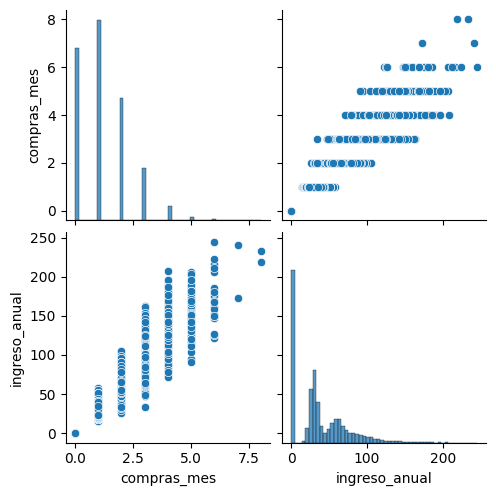

Ingreso anual en cero 4567


In [19]:
# Visualizar pares de variables con relaciones moderadas o fuertes

df2=df[['compras_mes','ingreso_anual']]
sns.pairplot(df2)
plt.show()

cantidad_ceros = ( df['ingreso_anual'] == 0).sum()
print('Ingreso anual en cero', cantidad_ceros)

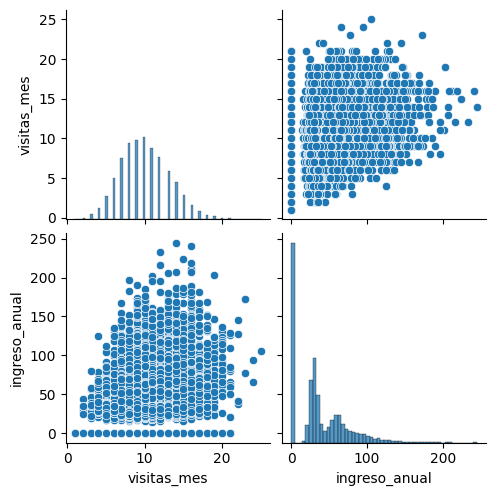

In [20]:
df2=df[['visitas_mes','ingreso_anual']]
sns.pairplot(df2)
plt.show()

✍️ **Comentario**:
Incluye qué ves: dirección (positiva o negativa), dispersión (alta, media, baja), presencia de outliers y posible colinealidad.

Observaciones iniciales (Scatterplot)

**compras_mes vs ingreso_anual**
- Dirección diagonal positiva.
- Outliers: puntos que se alejan del resto de la nube. Existen clientes con comportamiento atípico en esa relación. 4567 de 15000 clientes (aproximadamente un 30%) tienen ingreso_anual igual a 0. Eso es un porcentaje bastante alto, no es un par de valores atípicos sueltos, sino un patrón que vale la pena analizar.
- El patrón en bandas se debe a que ambas son variables discretas con rango acotado, no indica un problema con los datos.

**visitas_mes vs ingreso_anual'**
- Dirección diagonal positiva. Con outliers para analizar.

<div class="alert alert-block alert-danger">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

Los gráficos no muestran los dos pares clave de la solución: `compras_mes` vs `ingreso_anual` y `visitas_mes` vs `ingreso_anual`. Sustituye los pares explorados y describe sus patrones.
</div>

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

Correlación Pearson: 0.5789472719412829
Correlación Spearman: 0.5592673242622609


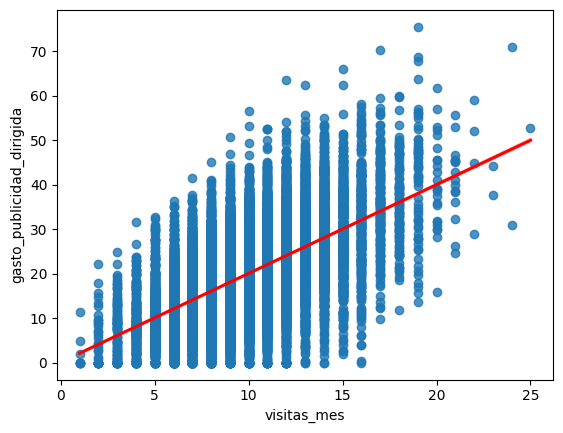

In [21]:
# Calcular correlación entre variables relevantes
# Calcular correlación Pearson
corr_colinealidad = df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='pearson')

# Mostrar resultado
print("Correlación Pearson:", corr_colinealidad)

# Calcular correlación Spearman
corr_colinealidad = df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='spearman')

# Mostrar resultado
print("Correlación Spearman:", corr_colinealidad)

sns.regplot(data=df, x="visitas_mes", y="gasto_publicidad_dirigida", line_kws={"color": "red"})
plt.show()


Correlación Pearson: 0.9671485435708558
Correlación Spearman: 0.9674824920326731


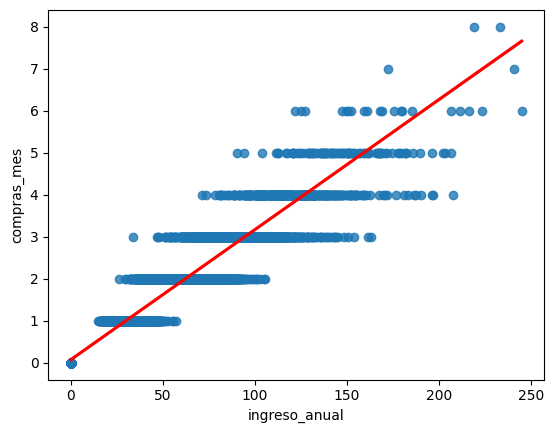

In [22]:
# Calcular correlación Pearson
corr_colinealidad = df['ingreso_anual'].corr(df['compras_mes'], method='pearson')

# Mostrar resultado
print("Correlación Pearson:", corr_colinealidad)

# Calcular correlación Spearman
corr_colinealidad = df['ingreso_anual'].corr(df['compras_mes'], method='spearman')

# Mostrar resultado
print("Correlación Spearman:", corr_colinealidad)

sns.regplot(data=df, x="ingreso_anual", y="compras_mes", line_kws={"color": "red"})
plt.show()

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.  
Incluye qué ves: dirección, magnitud y posible colinealidad.


Observaciones de correlación

*visitas_mes vs gasto_publicidad_dirigida*
- Existe correlación moderada entre visitas_mes y gasto_publicidad_dirigida.
- Correlación Pearson: 0.5789472719412827
  Correlación Spearman: 0.5592673242622609
- Esta interrelación es conveniente estudiarla para determinar posibles causas de su crecimiento similar.

**ingreso_anual vs compras_mes**

- Correlación lineal ascendente positiva, donde su fuerte correlación empírica las hace redundantes para el análisis, y habría que considerar quedarse con solo una de las dos (o investigar por qué están tan ligadas) antes de deducir por ello una causalidad.

- Correlación Pearson: 0.9671485435708566
  Correlación Spearman: 0.9674824920326731


### Punto-biserial

In [26]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr

print('miembro_premium vs compras_mes', pointbiserialr( df["miembro_premium"], df["compras_mes"] ))
print('abandono vs satisfaccion', pointbiserialr( df["abandono"], df["satisfaccion"] ))


miembro_premium vs compras_mes SignificanceResult(statistic=np.float64(0.0034305369677069017), pvalue=np.float64(0.6743981744115357))
abandono vs satisfaccion SignificanceResult(statistic=np.float64(-0.023832560673804043), pvalue=np.float64(0.003510976893362256))


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

Observaciones Punto-biserial

**miembro_premium vs compras_mes**
- Relación es casi nula con una valor de 0.003

**abandono vs satisfaccion**
- Relación debil, no es posible establecer claramente una causalidad entre el abandono y el nivel de satisfacción.

### V de Cramér

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.
Incluye qué ves

Observaciones V de Cramér



In [25]:
# Función para calcular V de Cramér
import numpy as np
from scipy.stats import chi2_contingency
tabla = pd.crosstab(df["region"], df["tipo_dispositivo"])
chi2, p, dof, expected = chi2_contingency(tabla)
n = tabla.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))
print("V de Cramér:", cramers_v)

V de Cramér: 0.012378338407739397


✍️ Comentario: Observaciones V de Cramér  0.0124 es una relación muy débil, no hay relación entonces clara entre ambas variables categóricas, por lo que sería necesario para profundizar, realizar una segmentación.

## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---

### Hallazgo 1 — ingreso_anual vs compras_mes

**Evidencia visual:**   

"El scatterplot (3.3) muestra una tendencia ascendente clara: a medida que aumenta el ingreso_anual las compras_mes tienden a aumentar también. Al ser pocos los valores de compras, los puntos forman barras, con outliers a tener en cuenta.

Es compras_mes quien toma pocos valores discretos (0,1,2,3...8) formando bandas horizontales, dentro de las cuales ingreso_anual varía. El patrón en bandas se debe a que ambas son variables discretas con rango acotado, no indica un problema con los datos.

**Evidencia numérica:**

Existen clientes con comportamiento atípico en esa relación. 4567 de 15000 clientes (aproximadamente un 30%) tienen ingreso_anual igual a 0. Eso es un porcentaje bastante alto, no es un par de valores atípicos sueltos, sino un patrón que vale la pena analizar.

- Correlación lineal ascendente positiva, donde su fuerte correlación empírica las hace redundantes para el análisis, y habría que considerar quedarse con solo una de las dos (o investigar por qué están tan ligadas) antes de deducir por ello una causalidad.

- Correlación Pearson: 0.9671485435708566
  Correlación Spearman: 0.9674824920326731

**Interpretación**  

Se observa que los valores de ingreso_anual y compras_mes se mueven juntas de manera ascendente positiva. Tienden a aumentar juntas, quizas se entendería mejor esta relación si se analizaran otras factores como el tipo de membresía o el poder adquisitivo. El poder adquisitivo de un cliente podría explicar que tenga tanto mayor ingreso anual como más compras mensuales, sin que una de estas variables cause directamente a la otra.

**No podemos afirmar**  

Que si se aumentan las compras también necesariamente aumentan los ingresos anuales.  Tal vez no es que comprar más "cause" directamente que el ingreso suba, sino que ambas variables podrían estar siendo influenciadas por una tercera variable que no estamos midiendo directamente. Por ejemplo, un cliente con mayor poder adquisitivo tiende tanto a comprar más veces como a generar más ingreso, simplemente porque tiene más capacidad de gasto en general — no porque "comprar más" sea la causa de "generar más ingreso"

**Implicación de negocio**  

Usar compras_mes como señal temprana para identificar clientes de alto valor.

Como estas dos columnas están fuertemente relacionadas, recomiendo tener en cuenta el factor de si es cliente_premium para reforzar las campañas publicitarias.

Se puede profundicar en la segmentación de los clientes por edades o por dispositivos o regiones para enfocar mas exactamente los esfuerzos de mercadeo.

### Hallazgo 2 — visitas_mes vs gasto_publicidad_dirigida

**Evidencia visual:**   
Mirando el scatterplot de visitas_mes vs gasto_publicidad_dirigida,  la forma en que se distribuyen los puntos forman una nube con dispersión moderada con algunos outliers, con una tendencia lineal positiva.

**Evidencia numérica:**
La Correlación Pearson: 0.579 y la Correlación Spearman: 0.559 confirman la dispersión moderada ya descrita. Pearson y Spearman son muy parecidos (0.579 vs 0.559), lo que indica que la relación es bastante lineal.  

**Interpretación**  
Es posible que una temporada especial (como fin de año, festividades) haya impulsado tanto el crecimiento de las visitas como de la inversión en publicidad, sin que su crecimiento similar dependa el uno del otro.

**No podemos afirmar**  
Que el crecimiento de las visitas_mes dependa del aumento de gasto_publicidad_dirigida, pues pueden haber otros factores que incidan como temporadas especiales durante el año o un cambio de membresía.

**Implicación de negocio**  
Antes de aumentar el gasto en publicidad dirigida esperando más visitas, se recomienda validar la relación con un test A/B (comparando tiendas con y sin campaña) o analizando el gasto separado por temporada, para aislar su efecto real.

## Sección 6 - Limitaciones y próximos pasos

✍️ **Comentario**: Completa el siguiente bloque.   
Modifica según creas necesario.  

Recuerda eliminar este bloque de texto antes de incluir el proyecto en tu portafolio.

### **Limitaciones**
- Correlación ≠ causalidad: Este análisis ha mostrado que si dos variables aumentan juntas, como  visitas_mes y gasto_publicidad_dirigida, no significa que una cause la otra directamente; ambas podrían estar influenciadas por una tercera como la temporada o eventos especiales.
- Este análisis se centró en observar correlaciones entre pares de variables, por lo que no se puede descartar la influencia de terceras variables no incluidas (como la temporada o el poder adquisitivo) que podrían explicar, en parte, las relaciones encontradas.

### **Próximos pasos**

Como próximo paso, se recomienda complementar este análisis con segmentaciones por dispositivo o región, así como estudios controlados (como test A/B) para aislar el efecto de variables específicas.

También sería valioso aplicar modelos de regresión múltiple que permitan controlar simultáneamente el efecto de varias variables, ayudando a aislar mejor las relaciones encontradas.
